
STEP 1 - LOADING THE DATA


100%|██████████| 172k/172k [00:00<00:00, 392kB/s]

Extracting files...


Downloaded from Kaggle: /root/.cache/kagglehub/datasets/avikasliwal/used-cars-price-prediction/versions/2/train-data.csv
Raw shape: (6019, 14)

STEP 2 - DATA CLEANING & FEATURE ENGINEERING
Removed 0 duplicate rows
Target (price) column: Price
Created 'brand' and 'model' from 'Name'
Created 'car_age' and 'km_per_year' (from 'Kilometers_Driven')

Cleaned shape: (5904, 14)

Missing values per column:
Mileage      2
Engine      35
Power      132
Seats       41

STEP 3 - EXPLORATORY DATA ANALYSIS
count    5904.00
mean        8.93
std         9.22
min         0.90
25%         3.50
50%         5.63
75%         9.75
max        56.00


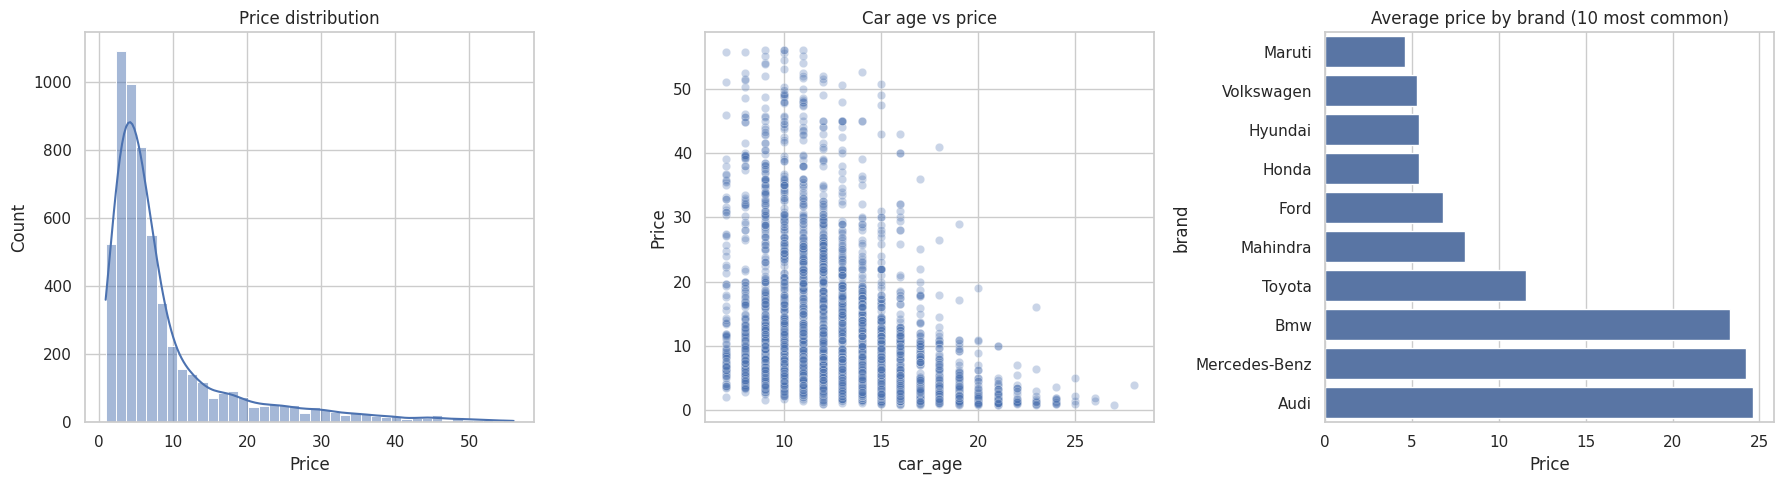

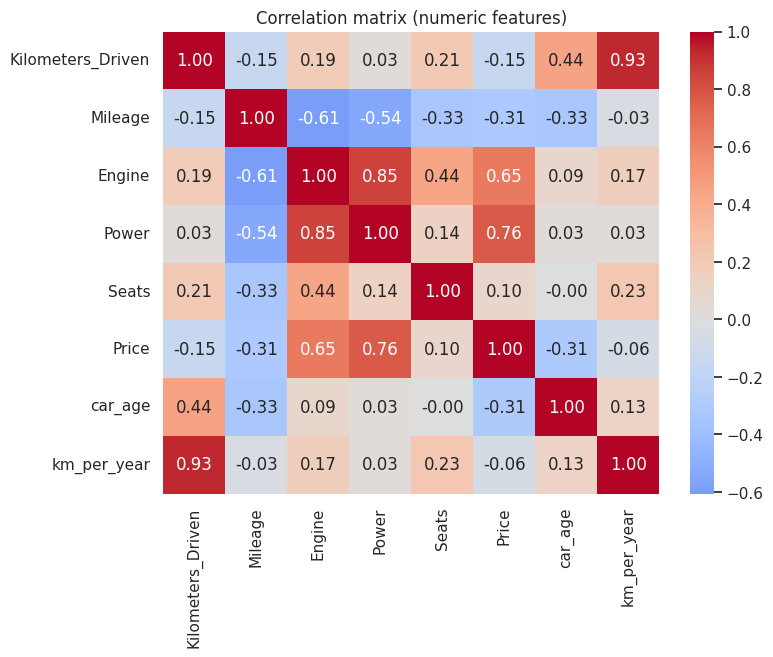


STEP 4 - TRAIN / TEST SPLIT
Numeric features    : ['Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'car_age', 'km_per_year']
Categorical features: ['Location', 'Fuel_Type', 'Transmission', 'Owner_Type', 'brand', 'model']

Training cars: 4723   |   Test cars (never seen in training): 1181

STEP 5 - MODEL COMPARISON (5-fold cross-validation on training data)
  finished: Ridge Regression
  finished: Random Forest
  finished: Extra Trees
  finished: Gradient Boosting

Cross-validation results:
            Model  CV R2 (%)  R2 std (%)  CV MAE
Gradient Boosting      92.13        1.60    1.18
      Extra Trees      91.92        1.97    1.20
 Ridge Regression      90.68        2.21    1.27
    Random Forest      90.46        2.19    1.29


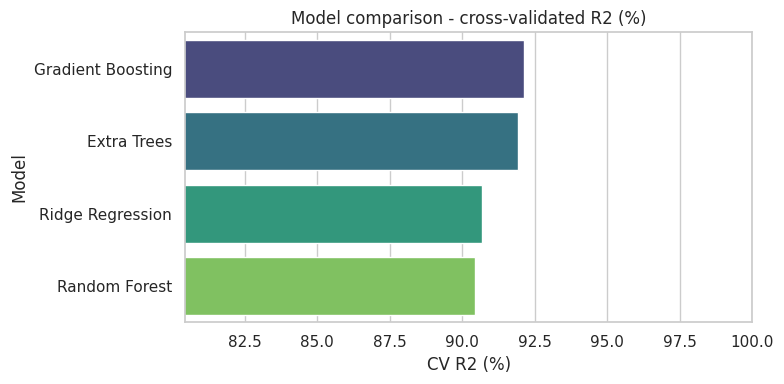


Best model so far: Gradient Boosting

STEP 6 - HYPER-PARAMETER TUNING
Tuning 'Gradient Boosting' with 20 random combinations (3-fold CV)...
Best parameters:
   min_samples_leaf: 10
   max_leaf_nodes: 31
   max_iter: 600
   learning_rate: 0.08
   l2_regularization: 0
Best CV R2 while tuning: 91.87 %

STEP 7 - FINAL EVALUATION ON UNSEEN TEST DATA
(The default settings performed better than the tuned ones - keeping them.)

Default settings
----------------
  R2 score (%)                    :      95.00
  Accuracy = 100 - MAPE (%)       :      87.49
  MAPE (%)                        :      12.51
  MAE                             :       1.09
  RMSE                            :       2.21
  Within 10% of real price (%)    :      56.56
  Within 20% of real price (%)    :      83.49

FINAL MODEL: Gradient Boosting
------------------------------
  R2 score (%)                    :      95.00
  Accuracy = 100 - MAPE (%)       :      87.49
  MAPE (%)                        :      12.51
  MAE   

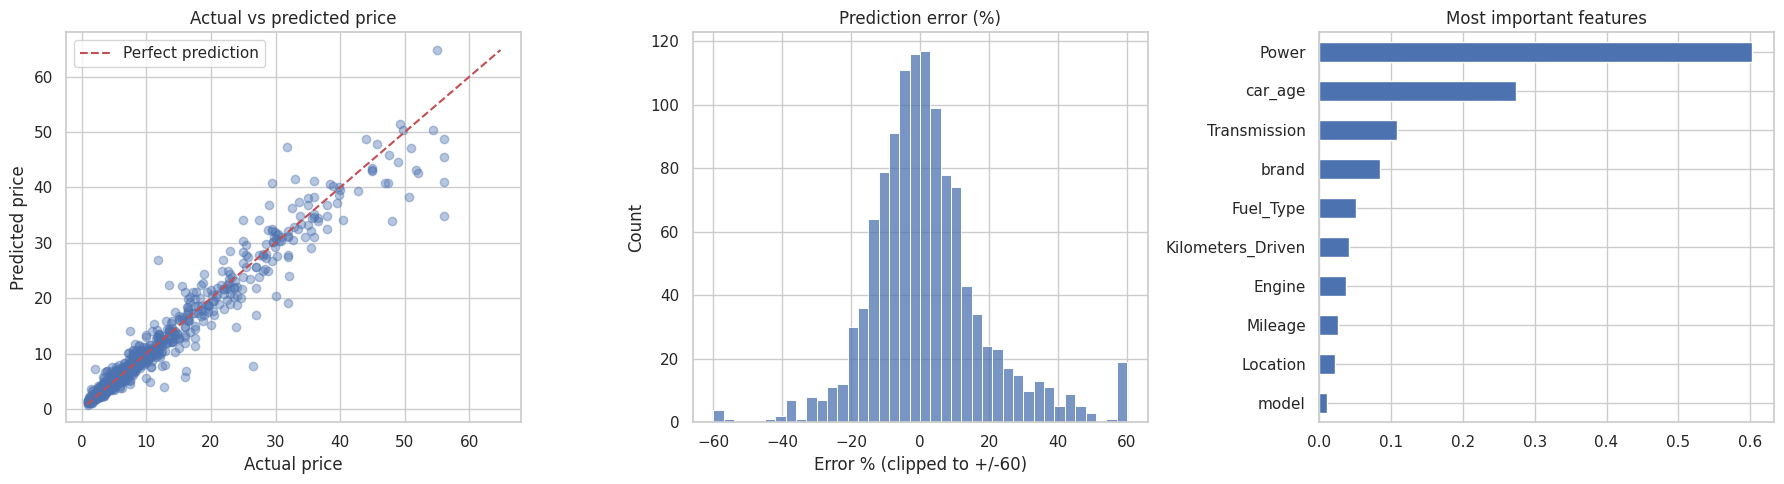


STEP 8 - TESTING ON DIFFERENT BRANDS / CAR TYPES
Accuracy per brand (brands with at least 10 test cars):
               cars_tested  avg_actual_price  avg_abs_error_%  accuracy_%  within_20%_%
brand                                                                                  
Maruti               230.0              4.43            10.30       89.70         88.26
Hyundai              214.0              5.63            11.58       88.42         86.45
Honda                116.0              5.58             9.60       90.40         87.93
Toyota                90.0             11.98            11.99       88.01         85.56
Ford                  65.0              7.31            14.94       85.06         78.46
Mercedes-Benz         63.0             27.57            15.33       84.67         76.19
Volkswagen            61.0              5.22             9.70       90.30         91.80
Bmw                   59.0             24.05            13.79       86.21         81.36
Mahindra      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# =====================================================================
#  USED CAR PRICE PREDICTION  -  Machine Learning Project (Google Colab)
# ---------------------------------------------------------------------
#  Goal   : Predict the average price of a used car from its brand,
#           model, age (year), kilometers driven and other features.
#  Steps  : 1) Setup & configuration       6) Model comparison (cross-validation)
#           2) Load data from Kaggle       7) Hyper-parameter tuning
#           3) Cleaning & feature eng.     8) Final test evaluation (accuracy %)
#           4) Exploratory analysis        9) Per-brand testing & sample cars
#           5) Train / test split         10) Predict your own car & save model
#
#  HOW TO USE: copy every block that starts with "# %%" into its own
#  Colab cell and run the cells in order.
# =====================================================================


# %% [1] Install libraries ----------------------------------------------------
!pip -q install kagglehub


# %% [2] Configuration --------------------------------------------------------
# Kaggle dataset used by the notebook "gcdatkin/used-car-price-prediction".
# To double-check it: open that notebook -> "Input" panel on the right -> click the
# dataset name -> copy the part of the URL after /datasets/  (owner/dataset-name).
DATASET_SLUG = "avikasliwal/used-cars-price-prediction"

TARGET_COL        = None   # price column name; None = detect automatically
RANDOM_STATE      = 42
TEST_SIZE         = 0.20   # 20 % of the data is kept for the final test
CV_FOLDS          = 5      # folds for cross-validation
TUNE_MODEL        = True   # hyper-parameter tuning (a few minutes)
TUNE_ITERATIONS   = 20     # random search iterations
MIN_BRAND_SAMPLES = 10     # min. test cars per brand in the per-brand report
N_SAMPLE_BRANDS   = 10     # how many different brands to show in sample predictions


# %% [3] Imports & helper functions -------------------------------------------
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     RandomizedSearchCV, ParameterGrid)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")


def section(title):
    """Print a clear section header."""
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def evaluate(y_true, y_pred):
    """Return all accuracy metrics (as a dict) for a set of predictions."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ape = np.abs(y_true - y_pred) / y_true            # absolute percentage error
    mape = ape.mean() * 100
    return {
        "R2 score (%)":            r2_score(y_true, y_pred) * 100,
        "Accuracy = 100 - MAPE (%)": max(0.0, 100 - mape),
        "MAPE (%)":                mape,
        "MAE":                     mean_absolute_error(y_true, y_pred),
        "RMSE":                    np.sqrt(mean_squared_error(y_true, y_pred)),
        "Within 10% of real price (%)": (ape <= 0.10).mean() * 100,
        "Within 20% of real price (%)": (ape <= 0.20).mean() * 100,
    }


def print_metrics(title, metrics):
    print(f"\n{title}")
    print("-" * len(title))
    for k, v in metrics.items():
        print(f"  {k:<32}: {v:10.2f}")


# %% [4] Load the data --------------------------------------------------------
section("STEP 1 - LOADING THE DATA")


def load_data(slug):
    """Download the dataset from Kaggle. If that fails, ask for a manual CSV upload."""
    try:
        import kagglehub
        path = kagglehub.dataset_download(slug)
        csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
        if not csv_files:
            raise FileNotFoundError("No CSV file found inside the dataset.")
        csv_files.sort(key=os.path.getsize, reverse=True)   # biggest file = main data
        print("Downloaded from Kaggle:", csv_files[0])
        return pd.read_csv(csv_files[0])
    except Exception as err:
        print("Could not download from Kaggle:", err)
        print("Please download the CSV from the dataset page and upload it here:")
        from google.colab import files as colab_files
        uploaded = colab_files.upload()
        return pd.read_csv(next(iter(uploaded)))


raw_df = load_data(DATASET_SLUG)
print("Raw shape:", raw_df.shape)
raw_df.head()


# %% [5] Cleaning & feature engineering ---------------------------------------
section("STEP 2 - DATA CLEANING & FEATURE ENGINEERING")


def to_number(series):
    """Convert text such as '19.67 kmpl', '1582 CC' or '$12,500' to numbers."""
    cleaned = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(cleaned.str.extract(r"^\s*\$?\s*(-?\d+\.?\d*)")[0], errors="coerce")


def find_target(df, forced=None):
    if forced:
        return forced
    lower = {c.lower(): c for c in df.columns}
    for cand in ["price", "selling_price", "sellingprice", "sale_price", "price_usd"]:
        if cand in lower:
            return lower[cand]
    hits = [c for c in df.columns if "price" in c.lower()
            and "new" not in c.lower() and "present" not in c.lower()]
    if not hits:
        raise ValueError("Price column not found - set TARGET_COL in the configuration cell.")
    return hits[0]


def prepare_data(df, target_col=None):
    df = df.copy()
    df = df.loc[:, ~df.columns.str.contains(r"^Unnamed", case=False)]   # drop index columns
    df.columns = [c.strip() for c in df.columns]
    n_before = len(df)
    df = df.drop_duplicates()
    print(f"Removed {n_before - len(df)} duplicate rows")

    target = find_target(df, target_col)
    print("Target (price) column:", target)

    # --- brand & model from the car name ---------------------------------
    name_cols = [c for c in df.columns if c.lower() in ("name", "car_name", "car", "title")]
    for nc in name_cols:
        names = df[nc].astype(str).str.strip()
        for two_word in ["Land Rover", "Rolls Royce", "Aston Martin", "Alfa Romeo"]:
            names = names.str.replace(two_word, two_word.replace(" ", "-"), regex=False)
        tokens = names.str.split()
        df["brand"] = tokens.str[0].str.title()
        df["model"] = tokens.str[:2].str.join(" ").str.title()
        df = df.drop(columns=nc)
        print(f"Created 'brand' and 'model' from '{nc}'")

    # --- text columns that contain numbers + units -> numeric ------------
    for c in df.columns:
        if c == target or c in ("brand", "model"):
            continue
        if not pd.api.types.is_numeric_dtype(df[c]):
            converted = to_number(df[c])
            if df[c].notna().sum() > 0 and converted.notna().sum() >= 0.8 * df[c].notna().sum():
                df[c] = converted
    df[target] = pd.to_numeric(df[target], errors="coerce") if not pd.api.types.is_numeric_dtype(df[target]) else df[target]

    # --- year -> car age, km per year -------------------------------------
    year_cols = [c for c in df.columns if c.lower() in
                 ("year", "model_year", "registration_year", "manufacture_year")]
    if year_cols:
        yc = year_cols[0]
        df["car_age"] = (pd.Timestamp.today().year - df[yc]).clip(lower=0)
        df = df.drop(columns=yc)
        km_cols = [c for c in df.columns if any(k in c.lower() for k in
                   ("kilomet", "km_driven", "kms_driven", "odometer"))]
        if km_cols:
            df["km_per_year"] = df[km_cols[0]] / (df["car_age"] + 1)
            print(f"Created 'car_age' and 'km_per_year' (from '{km_cols[0]}')")

    # --- remove columns that are mostly empty or constant ------------------
    df = df.loc[:, df.isna().mean() < 0.6]
    df = df.loc[:, df.nunique(dropna=True) > 1]

    # --- clean the price: remove missing, zero and extreme values ----------
    df = df.dropna(subset=[target])
    df = df[df[target] > 0]
    low, high = df[target].quantile([0.01, 0.99])
    df = df[(df[target] >= low) & (df[target] <= high)]

    # --- make text columns plain 'object' with NaN (safe for scikit-learn) --
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

    return df.reset_index(drop=True), target


df, TARGET = prepare_data(raw_df, TARGET_COL)
print("\nCleaned shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0].to_string() or "  none")
df.head()


# %% [6] Exploratory data analysis --------------------------------------------
section("STEP 3 - EXPLORATORY DATA ANALYSIS")

print(df[TARGET].describe().round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df[TARGET], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Price distribution")

if "car_age" in df.columns:
    sns.scatterplot(x="car_age", y=TARGET, data=df, alpha=0.3, ax=axes[1])
    axes[1].set_title("Car age vs price")

if "brand" in df.columns:
    top_brands = df["brand"].value_counts().head(10).index
    order = df[df["brand"].isin(top_brands)].groupby("brand")[TARGET].mean().sort_values().index
    sns.barplot(x=TARGET, y="brand", data=df[df["brand"].isin(top_brands)],
                order=order, estimator=np.mean, errorbar=None, ax=axes[2])
    axes[2].set_title("Average price by brand (10 most common)")
plt.tight_layout()
plt.show()

numeric_part = df.select_dtypes(include="number")
if numeric_part.shape[1] > 2:
    plt.figure(figsize=(8, 6))
    sns.heatmap(numeric_part.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation matrix (numeric features)")
    plt.show()


# %% [7] Train / test split & preprocessing -----------------------------------
section("STEP 4 - TRAIN / TEST SPLIT")

X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features     = X.select_dtypes(include="number").columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
print("Numeric features    :", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print(f"\nTraining cars: {len(X_train)}   |   Test cars (never seen in training): {len(X_test)}")

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=3, sparse_output=False)),
    ]), categorical_features),
])


def build_model(regressor):
    """Preprocessing + regressor. We learn log(price) because prices are skewed;
    predictions are converted back to the real price automatically."""
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", preprocessor), ("reg", regressor)]),
        func=np.log1p, inverse_func=np.expm1)


# %% [8] Compare several models with cross-validation -------------------------
section("STEP 5 - MODEL COMPARISON (5-fold cross-validation on training data)")

candidates = {
    "Ridge Regression":    build_model(Ridge(alpha=1.0)),
    "Random Forest":       build_model(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)),
    "Extra Trees":         build_model(ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting":   build_model(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=RANDOM_STATE)),
}

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
    rows.append({
        "Model": name,
        "CV R2 (%)": scores["test_r2"].mean() * 100,
        "R2 std (%)": scores["test_r2"].std() * 100,
        "CV MAE": -scores["test_mae"].mean(),
    })
    print(f"  finished: {name}")

cv_table = pd.DataFrame(rows).sort_values("CV R2 (%)", ascending=False).reset_index(drop=True)
print("\nCross-validation results:")
print(cv_table.round(2).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(x="CV R2 (%)", y="Model", data=cv_table, palette="viridis")
plt.title("Model comparison - cross-validated R2 (%)")
plt.xlim(max(0, cv_table["CV R2 (%)"].min() - 10), 100)
plt.tight_layout()
plt.show()

best_name = cv_table.loc[0, "Model"]
print(f"\nBest model so far: {best_name}")


# %% [9] Hyper-parameter tuning ------------------------------------------------
section("STEP 6 - HYPER-PARAMETER TUNING")

param_spaces = {
    "Ridge Regression": {"regressor__reg__alpha": [0.01, 0.1, 1, 3, 10, 30]},
    "Random Forest": {
        "regressor__reg__n_estimators": [200, 300, 500],
        "regressor__reg__max_depth": [None, 10, 20, 30],
        "regressor__reg__min_samples_leaf": [1, 2, 4],
        "regressor__reg__max_features": [1.0, 0.5, "sqrt"]},
    "Extra Trees": {
        "regressor__reg__n_estimators": [200, 300, 500],
        "regressor__reg__max_depth": [None, 10, 20, 30],
        "regressor__reg__min_samples_leaf": [1, 2, 4],
        "regressor__reg__max_features": [1.0, 0.5, "sqrt"]},
    "Gradient Boosting": {
        "regressor__reg__learning_rate": [0.03, 0.05, 0.08, 0.1, 0.15],
        "regressor__reg__max_iter": [200, 400, 600],
        "regressor__reg__max_leaf_nodes": [15, 31, 63],
        "regressor__reg__min_samples_leaf": [5, 10, 20, 40],
        "regressor__reg__l2_regularization": [0, 0.1, 1, 10]},
}

baseline_model = candidates[best_name].fit(X_train, y_train)

if TUNE_MODEL:
    space = param_spaces[best_name]
    n_iter = min(TUNE_ITERATIONS, len(ParameterGrid(space)))
    print(f"Tuning '{best_name}' with {n_iter} random combinations (3-fold CV)...")
    search = RandomizedSearchCV(candidates[best_name], space, n_iter=n_iter, cv=3,
                                scoring="r2", random_state=RANDOM_STATE, n_jobs=1)
    search.fit(X_train, y_train)
    final_model = search.best_estimator_
    print("Best parameters:")
    for k, v in search.best_params_.items():
        print(f"   {k.replace('regressor__reg__', '')}: {v}")
    print(f"Best CV R2 while tuning: {search.best_score_ * 100:.2f} %")
else:
    final_model = baseline_model


# %% [10] Final evaluation on the unseen test set ------------------------------
section("STEP 7 - FINAL EVALUATION ON UNSEEN TEST DATA")

pred_base  = baseline_model.predict(X_test)
pred_final = final_model.predict(X_test)

m_base  = evaluate(y_test, pred_base)
m_final = evaluate(y_test, pred_final)

# keep whichever version (default / tuned) is better on R2
if m_base["R2 score (%)"] > m_final["R2 score (%)"]:
    final_model, pred_final, m_final = baseline_model, pred_base, m_base
    print("(The default settings performed better than the tuned ones - keeping them.)")

print_metrics("Default settings", m_base)
print_metrics(f"FINAL MODEL: {best_name}", m_final)

print("\n" + "#" * 78)
print(f"#  MODEL ACCURACY (R2 score)        : {m_final['R2 score (%)']:.2f} %")
print(f"#  PRICE ACCURACY (100 - MAPE)      : {m_final['Accuracy = 100 - MAPE (%)']:.2f} %")
print(f"#  Predictions within 10% of price  : {m_final['Within 10% of real price (%)']:.2f} %")
print(f"#  Predictions within 20% of price  : {m_final['Within 20% of real price (%)']:.2f} %")
print("#" * 78)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, pred_final, alpha=0.4)
lims = [min(y_test.min(), pred_final.min()), max(y_test.max(), pred_final.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Actual vs predicted price"); axes[0].legend()

errors = (pred_final - y_test) / y_test * 100
sns.histplot(errors.clip(-60, 60), bins=40, ax=axes[1])
axes[1].set_title("Prediction error (%)"); axes[1].set_xlabel("Error % (clipped to +/-60)")

imp = permutation_importance(final_model, X_test, y_test, n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=-1)
imp_series = pd.Series(imp.importances_mean, index=X.columns).sort_values().tail(10)
imp_series.plot(kind="barh", ax=axes[2], title="Most important features")
plt.tight_layout()
plt.show()


# %% [11] Testing on different brands & car types ------------------------------
section("STEP 8 - TESTING ON DIFFERENT BRANDS / CAR TYPES")

test_df = X_test.copy()
test_df["actual"] = y_test.values
test_df["predicted"] = pred_final
test_df["error_%"] = (test_df["predicted"] - test_df["actual"]) / test_df["actual"] * 100

if "brand" in test_df.columns:
    # --- accuracy per brand ----
    per_brand = (test_df.groupby("brand")
                 .apply(lambda g: pd.Series({
                     "cars_tested": len(g),
                     "avg_actual_price": g["actual"].mean(),
                     "avg_abs_error_%": g["error_%"].abs().mean(),
                     "accuracy_%": max(0, 100 - g["error_%"].abs().mean()),
                     "within_20%_%": (g["error_%"].abs() <= 20).mean() * 100}))
                 .query("cars_tested >= @MIN_BRAND_SAMPLES")
                 .sort_values("cars_tested", ascending=False))
    print(f"Accuracy per brand (brands with at least {MIN_BRAND_SAMPLES} test cars):")
    print(per_brand.round(2).to_string())

    # --- one sample car for each of the most common brands ----
    print("\nSample predictions - one car from each of the most common brands:")
    top = test_df["brand"].value_counts().head(N_SAMPLE_BRANDS).index
    samples = (test_df[test_df["brand"].isin(top)]
               .groupby("brand", group_keys=False)
               .apply(lambda g: g.sample(1, random_state=RANDOM_STATE)))
    show_cols = [c for c in ["brand", "model", "car_age"] if c in samples.columns] + \
                ["actual", "predicted", "error_%"]
    print(samples[show_cols].round(2).to_string(index=False))
else:
    print(test_df[["actual", "predicted", "error_%"]].head(15).round(2).to_string())

# --- cheap vs medium vs expensive cars ----
price_band = pd.qcut(test_df["actual"], 3, labels=["Cheap", "Medium", "Expensive"])
band_table = test_df.groupby(price_band).apply(lambda g: pd.Series({
    "cars_tested": len(g),
    "avg_abs_error_%": g["error_%"].abs().mean(),
    "within_20%_%": (g["error_%"].abs() <= 20).mean() * 100}))
print("\nAccuracy by price segment:")
print(band_table.round(2).to_string())


# %% [12] Predict the price of your own car -----------------------------------
section("STEP 9 - PREDICT THE PRICE OF YOUR OWN CAR")


def predict_price(**car):
    """Example: predict_price(brand='Toyota', model='Toyota Corolla', car_age=5, Kilometers_Driven=60000)
    Any feature you do not give is treated as unknown and filled automatically."""
    unknown = [k for k in car if k not in X.columns]
    if unknown:
        raise ValueError(f"Unknown feature(s) {unknown}. Available: {list(X.columns)}")
    row = pd.DataFrame([{c: car.get(c, np.nan) for c in X.columns}])
    return float(final_model.predict(row)[0])


print("Available features:", list(X.columns))
for c in categorical_features[:4]:
    print(f"  common values of '{c}':", X[c].dropna().value_counts().head(5).index.tolist())

# Edit the values below to match your car, then run the cell:
# my_price = predict_price(brand="Toyota", model="Toyota Corolla", car_age=5, Kilometers_Driven=60000)
# print(f"Estimated price: {my_price:,.2f}")


# %% [13] Save the model ------------------------------------------------------
section("STEP 10 - SAVE THE MODEL")

joblib.dump({"model": final_model, "features": list(X.columns), "metrics": m_final},
            "car_price_model.joblib")
print("Saved: car_price_model.joblib")
print("Load later with:  bundle = joblib.load('car_price_model.joblib')")

try:
    from google.colab import files
    files.download("car_price_model.joblib")
except Exception:
    pass